In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import math

from scipy.stats import pearsonr
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV


In [2]:
df = pd.read_csv("data_reg.csv")
print(df.head())

# If Date is in dd-mm-YYYY format, parse it like this:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# Make sure rows are in time order before using lag/shift
df = df.sort_values("Date").reset_index(drop=True)

         Date   Bund    BTP  DFR  ON-GcPooling  ON-ExtGcPooling  TN-GcPooling  \
0  24-02-2026  2.707  3.314  2.0         2.004            2.011         2.011   
1  23-02-2026  2.711  3.319  2.0         2.000            2.014         2.008   
2  20-02-2026  2.737  3.340  2.0         2.011            2.021         2.013   
3  19-02-2026  2.743  3.350  2.0         2.014            2.021         2.015   
4  18-02-2026  2.739  3.345  2.0         2.006            2.012         2.016   

   TN-ExtGcPooling  SN-GcPooling  SN-ExtGcPooling  ...  ON-GcPoolingVol  \
0            2.015         2.015            2.015  ...            21056   
1            2.016         2.011            2.019  ...            11000   
2            2.020         2.011            2.020  ...            14101   
3            2.020         2.015            2.020  ...            13490   
4            2.019         2.012            2.020  ...            17991   

   ON-ExtGcPoolingVol  TN-GcPoolingVol  TN-ExtGcPoolingVol  SN

In [3]:
df["ECB_deferred_rate_new"] = (
    df["ON-GcPooling"] * df["ON-GcPoolingVol"]
    + df["TN-GcPooling"].shift(1) * df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPooling"].shift(2) * df["SN-GcPoolingVol"].shift(2)
) / (
    df["ON-GcPoolingVol"]
    + df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPoolingVol"].shift(2)
)

df["ECB_deferred_vol_new"] = (
    df["ON-GcPoolingVol"]
    + df["TN-GcPoolingVol"].shift(1)
    + df["SN-GcPoolingVol"].shift(2)
)

df["EXT_deferred_rate_new"] = (
    df["ON-ExtGcPooling"] * df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPooling"].shift(1) * df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPooling"].shift(2) * df["SN-ExtGcPoolingVol"].shift(2)
) / (
    df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPoolingVol"].shift(2)
)

df["EXT_deferred_vol_new"] = (
    df["ON-ExtGcPoolingVol"]
    + df["TN-ExtGcPoolingVol"].shift(1)
    + df["SN-ExtGcPoolingVol"].shift(2)
)

# Spread
df["DeferredRateSpread"] = df["EXT_deferred_rate_new"] - df["ECB_deferred_rate_new"]

# BTP-Bund spread (this part you intended as subtraction)
df["BTP_Bund_Spread"] = df["BTP"] - df["Bund"]

df["ExcessLiquidityLn"] = np.log(df["ExcessLiquidity"])

#Volume Spread
df["Volume_Spread"] = df["ECB_deferred_vol_new"] - df["EXT_deferred_vol_new"]
df["Liquidity_ratio"] = np.log(df["ECB_deferred_vol_new"]/ df["EXT_deferred_vol_new"])

df.head()

C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Date,Bund,BTP,DFR,ON-GcPooling,ON-ExtGcPooling,TN-GcPooling,TN-ExtGcPooling,SN-GcPooling,SN-ExtGcPooling,...,MLF,ECB_deferred_rate_new,ECB_deferred_vol_new,EXT_deferred_rate_new,EXT_deferred_vol_new,DeferredRateSpread,BTP_Bund_Spread,ExcessLiquidityLn,Volume_Spread,Liquidity_ratio
0,2010-01-05,3.373,4.101,0.25,0.293,0.319,0.326,0.330,0.335,0.330,...,1.75,NaN,NaN,NaN,NaN,NaN,0.728,12.189160,NaN,NaN
1,2010-01-06,3.381,4.120,0.25,0.274,0.313,0.295,0.316,0.335,0.319,...,1.75,NaN,NaN,NaN,NaN,NaN,0.739,12.042477,NaN,NaN
2,2010-01-07,3.370,4.094,0.25,0.283,0.308,0.290,0.304,0.305,0.318,...,1.75,0.296702,10845.0,0.317555,2407.0,0.020853,0.724,12.061267,8438.0,1.505323
3,2010-01-08,3.385,4.078,0.25,0.282,0.319,0.324,0.321,0.327,0.323,...,1.75,0.285156,14131.0,0.314854,3075.0,0.029697,0.693,12.061267,11056.0,1.525066
4,2010-01-11,3.347,4.057,0.25,0.264,0.280,0.294,0.293,0.318,0.320,...,1.75,0.283652,13776.0,0.318093,2423.0,0.034442,0.710,12.111537,11353.0,1.737922


In [6]:
#Conver to basis points
rate_cols = [
    "Bund", "BTP", 
    "ON-GcPooling", "ON-ExtGcPooling",
    "TN-GcPooling", "TN-ExtGcPooling",
    "SN-GcPooling", "SN-ExtGcPooling",
    "DeferredRate",
    "ECB_deferred_rate_new", "EXT_deferred_rate_new",
    "DeferredRateSpread", "BTP_Bund_Spread","DFR"
]

df[rate_cols] = df[rate_cols] * 100

In [7]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
df = df.sort_values("Date").copy()
df=df.dropna()
df.columns
df.head()

,Date,Bund,BTP,DFR,ON-GcPooling,ON-ExtGcPooling,TN-GcPooling,TN-ExtGcPooling,SN-GcPooling,SN-ExtGcPooling,...,MLF,ECB_deferred_rate_new,ECB_deferred_vol_new,EXT_deferred_rate_new,EXT_deferred_vol_new,DeferredRateSpread,BTP_Bund_Spread,ExcessLiquidityLn,Volume_Spread,Liquidity_ratio
2,2010-01-07,337.0,409.4,25.0,28.3,30.8,29.0,30.4,30.5,31.8,...,1.75,29.670217,10845.0,31.755546,2407.0,2.085330,72.4,12.061267,8438.0,1.505323
3,2010-01-08,338.5,407.8,25.0,28.2,31.9,32.4,32.1,32.7,32.3,...,1.75,28.515618,14131.0,31.485366,3075.0,2.969748,69.3,12.061267,11056.0,1.525066
4,2010-01-11,334.7,405.7,25.0,26.4,28.0,29.4,29.3,31.8,32.0,...,1.75,28.365157,13776.0,31.809327,2423.0,3.444170,71.0,12.111537,11353.0,1.737922
5,2010-01-12,331.3,405.5,25.0,25.2,27.9,26.2,28.1,27.7,29.2,...,1.75,27.985336,16885.0,29.925233,3646.0,1.939897,74.2,12.138917,13239.0,1.532795
6,2010-01-13,330.3,408.9,25.0,25.3,26.1,26.2,27.0,26.5,27.5,...,1.75,27.346796,12875.0,28.502926,3760.0,1.156129,78.6,12.180539,9115.0,1.230868


In [53]:
df2 = df[[
    "Date",
    "ExcessLiquidity",
    "ExcessLiquidityLn",
    "BTP_Bund_Spread",
    "DeferredRateSpread",
    "ECB_deferred_vol_new",
    "EXT_deferred_vol_new",
    "Liquidity_ratio",
        "DFR","MRO","MLF",
    "ECB_deferred_rate_new", "EXT_deferred_rate_new", "DeferredVol", "DeferredRate"
    #"Stress_State"
]].dropna().copy()

df2 = df2(df2['Date'] >='2012-01-01') 

# 1. Define the outlier boundaries (1st and 99th percentiles)
lower_cutoff = df2['DeferredRateSpread'].quantile(0.05)
upper_cutoff = df2['DeferredRateSpread'].quantile(0.95)

# 2. Create the cleaned dataframe
# We use .copy() to ensure we aren't working on a slice of the original df
df3 = df2[(df2['DeferredRateSpread'] > lower_cutoff) & 
               (df2['DeferredRateSpread'] < upper_cutoff)].copy()

df3["Deferred_MA"] = df3["DeferredRateSpread"].rolling(window=5).mean()

TypeError: 'DataFrame' object is not callable

In [51]:
df3['d_log_Excess'] = df3['ExcessLiquidityLn'].diff()

# Plots

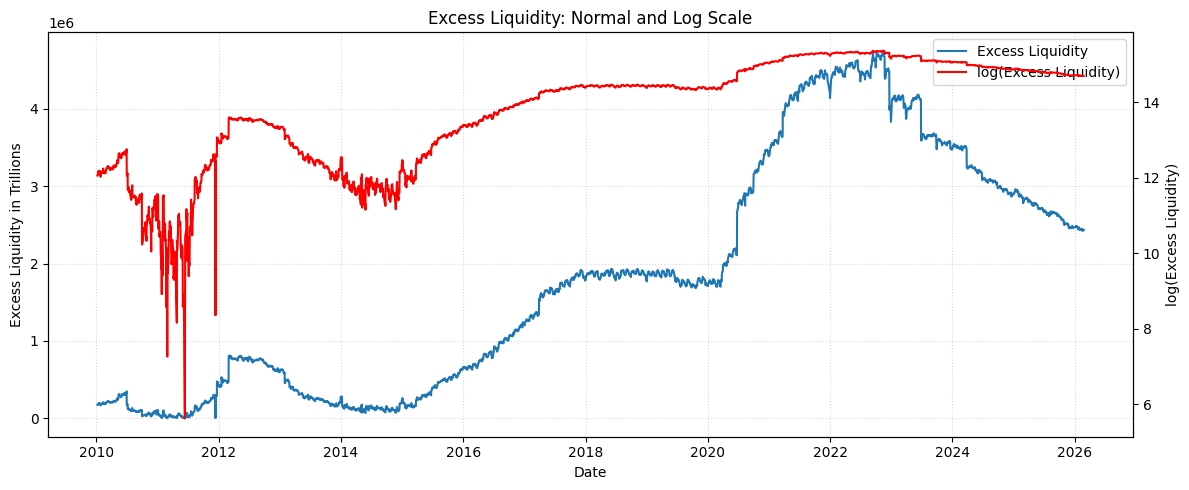

In [47]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df["Date"], df["ExcessLiquidity"], label="Excess Liquidity")
ax1.set_xlabel("Date")
ax1.set_ylabel("Excess Liquidity in Trillions")

ax2 = ax1.twinx()
ax2.plot(df["Date"], df["ExcessLiquidityLn"], label="log(Excess Liquidity)", color = "red")
ax2.set_ylabel("log(Excess Liquidity)")

ax1.set_title("Excess Liquidity: Normal and Log Scale")
ax1.grid(True, linestyle="dotted", alpha=0.5)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()


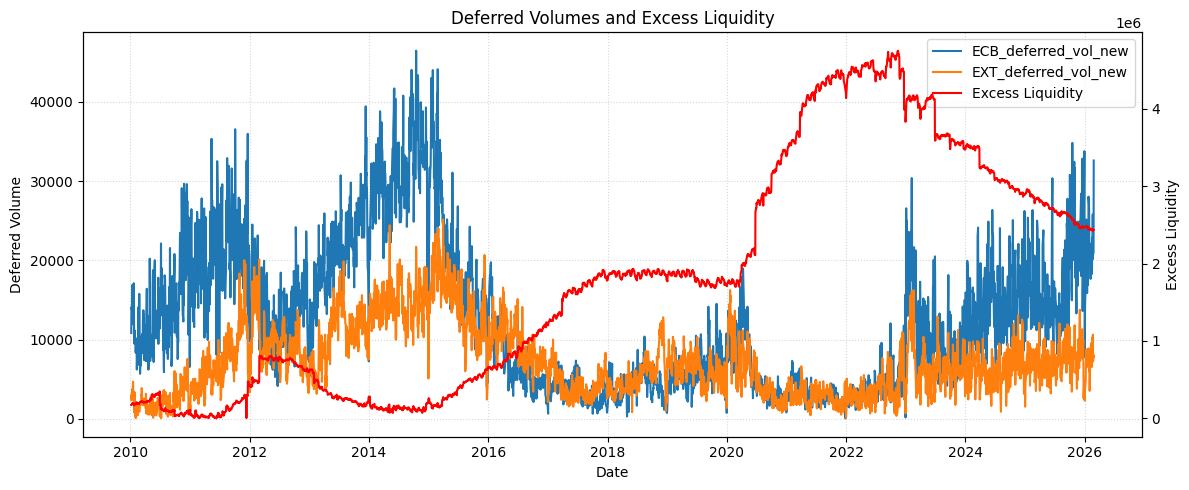

In [34]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df["Date"], df["ECB_deferred_vol_new"], label="ECB_deferred_vol_new")
ax1.plot(df["Date"], df["EXT_deferred_vol_new"], label="EXT_deferred_vol_new")
ax1.set_xlabel("Date")
ax1.set_ylabel("Deferred Volume")

ax2 = ax1.twinx()
ax2.plot(df["Date"], df["ExcessLiquidity"], label="Excess Liquidity", color="red")
ax2.set_ylabel("Excess Liquidity")

ax1.set_title("Deferred Volumes and Excess Liquidity")
ax1.grid(True, linestyle="dotted", alpha=0.5)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()


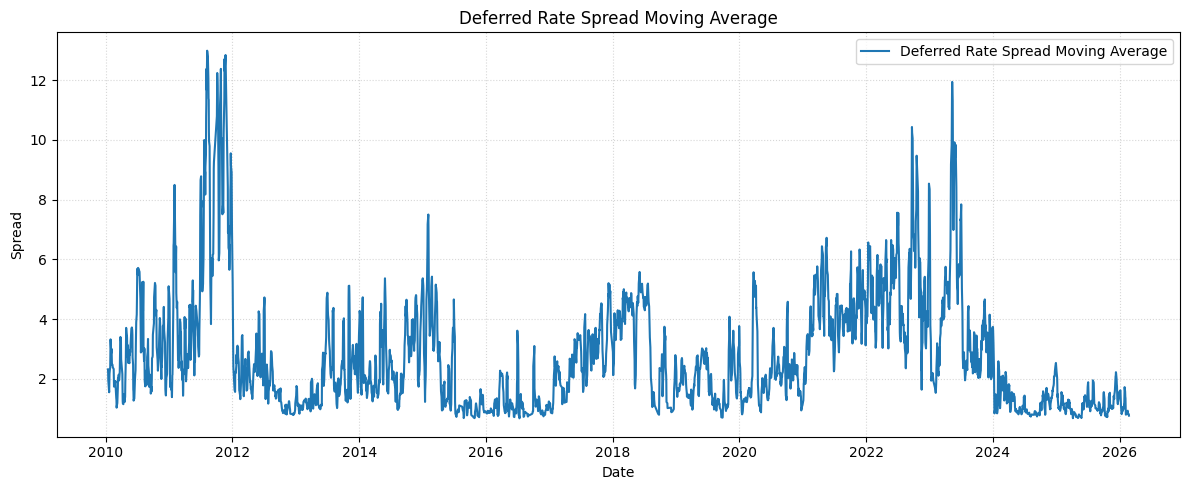

In [46]:
plt.figure(figsize=(12, 5))
plt.plot(df3["Date"], df3["Deferred_MA"], label="Deferred Rate Spread Moving Average")
plt.title("Deferred Rate Spread Moving Average")
plt.xlabel("Date")
plt.ylabel("Spread")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

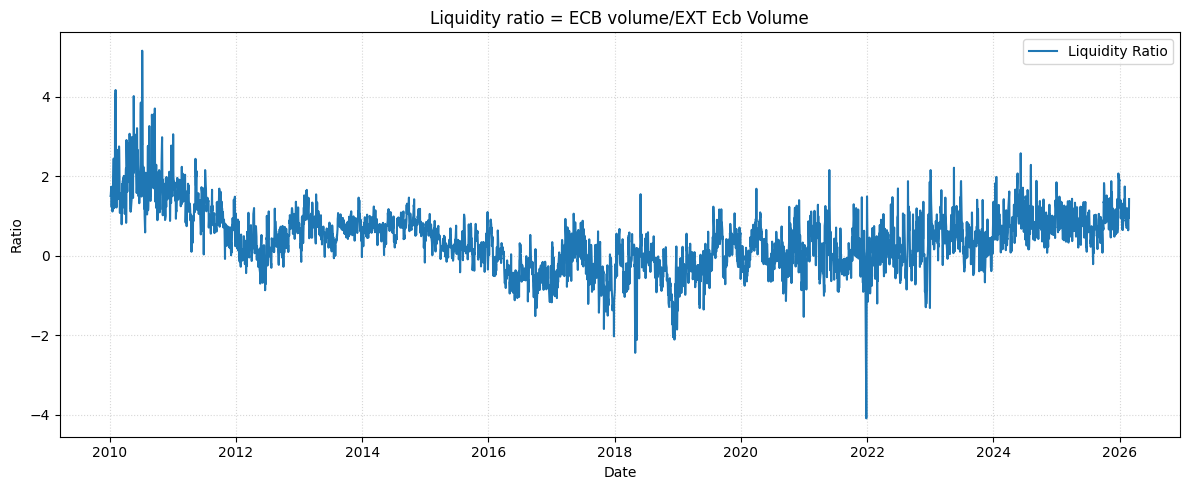

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Liquidity_ratio"], label="Liquidity Ratio")
plt.title("Liquidity ratio = ECB volume/EXT Ecb Volume")
plt.xlabel("Date")
plt.ylabel("Ratio")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

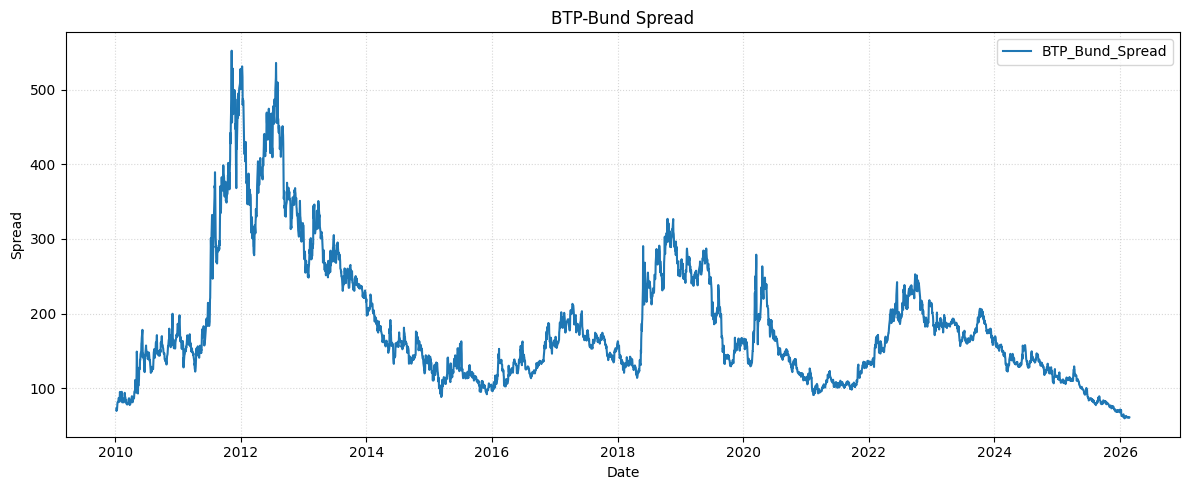

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["BTP_Bund_Spread"], label="BTP_Bund_Spread")
plt.title("BTP-Bund Spread")
plt.xlabel("Date")
plt.ylabel("Spread")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

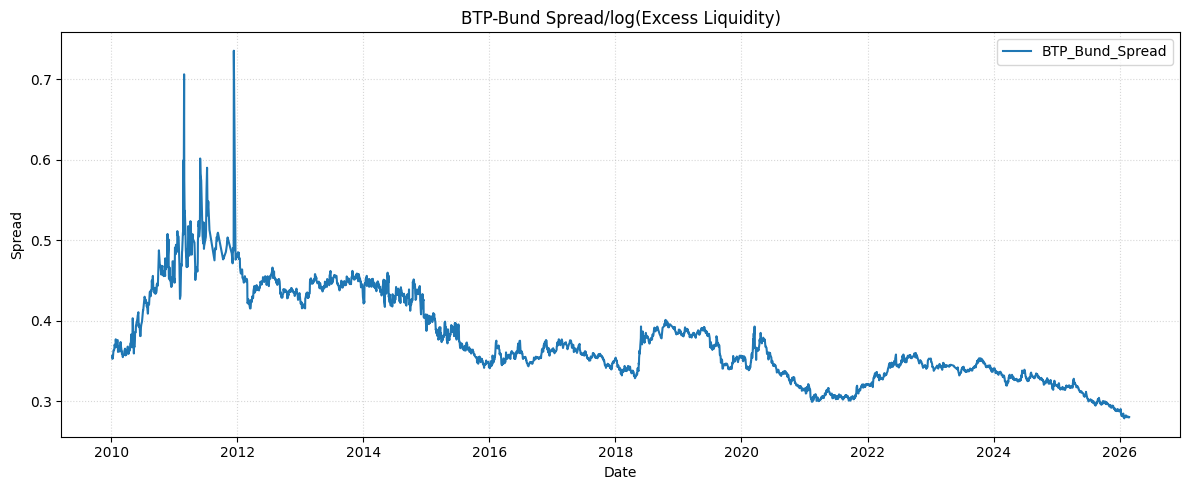

In [23]:
plt.figure(figsize=(12, 5))
plt.plot(df3["Date"], df3["ratio"], label="BTP_Bund_Spread")
plt.title("BTP-Bund Spread/log(Excess Liquidity)")
plt.xlabel("Date")
plt.ylabel("Spread")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

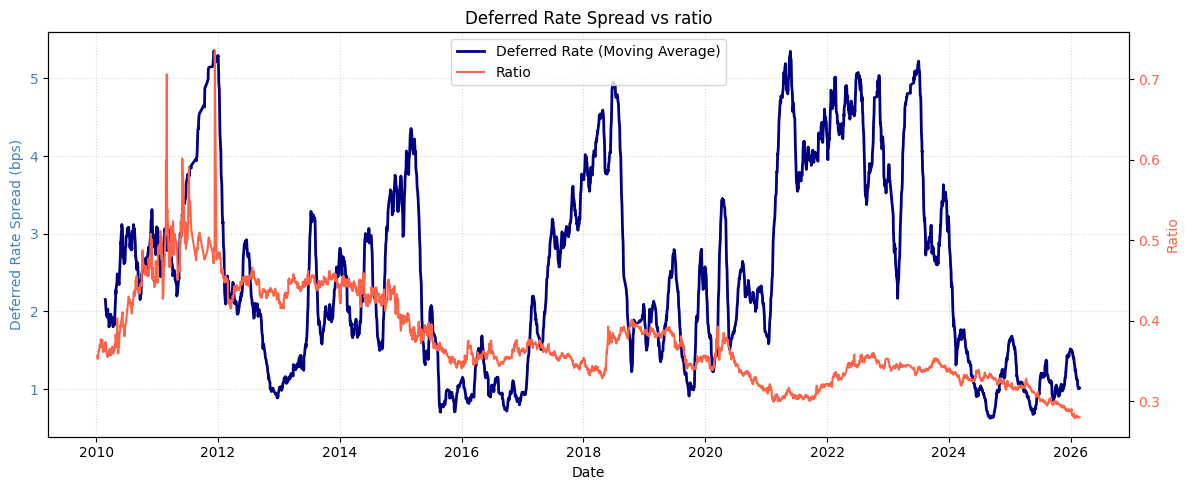

In [26]:
fig, ax1 = plt.subplots(figsize=(12, 5))
# Primary axis (left)
#ax1.plot(df3["Date"], df3["DeferredRateSpread"],
         #label="Deferred Rate (raw)", color="steelblue", alpha=0.4)

ax1.plot(df3["Date"], df3["Deferred_MA"],
         label="Deferred Rate (Moving Average)", color="navy", linewidth=2)

ax1.set_xlabel("Date")
ax1.set_ylabel("Deferred Rate Spread (bps)", color="steelblue")
ax1.tick_params(axis='y', labelcolor="steelblue")

# Secondary axis (right)
ax2 = ax1.twinx()
ax2.plot(df3["Date"], df3["ratio"],
         label="Ratio", color="tomato")
ax2.set_ylabel("Ratio", color="tomato")
ax2.tick_params(axis='y', labelcolor="tomato")

# Title + grid
ax1.set_title("Deferred Rate Spread vs ratio")
ax1.grid(True, linestyle="dotted", alpha=0.5)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

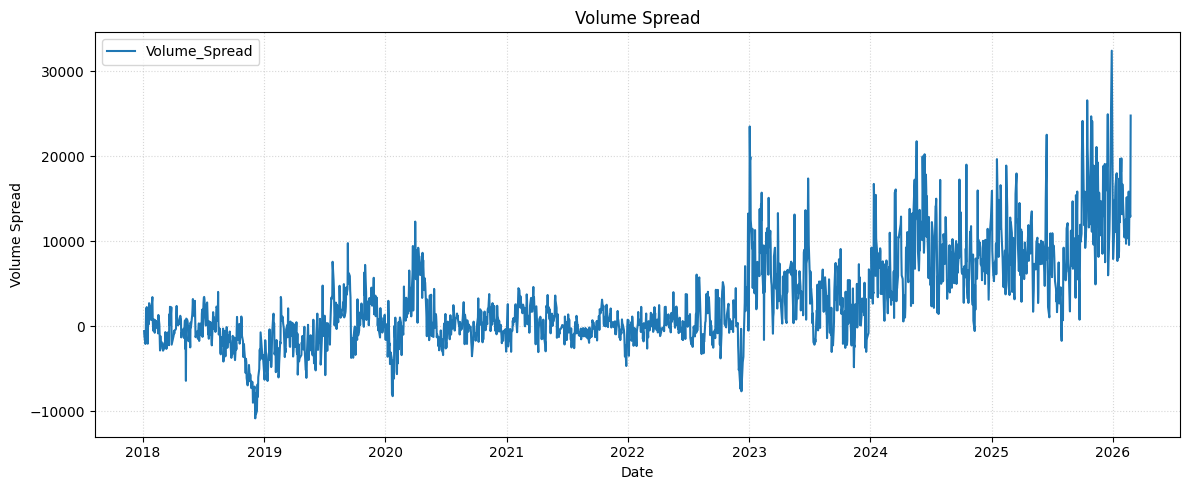

In [322]:
plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Volume_Spread"], label="Volume_Spread")

plt.title("Volume Spread")
plt.xlabel("Date")
plt.ylabel("Volume Spread")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

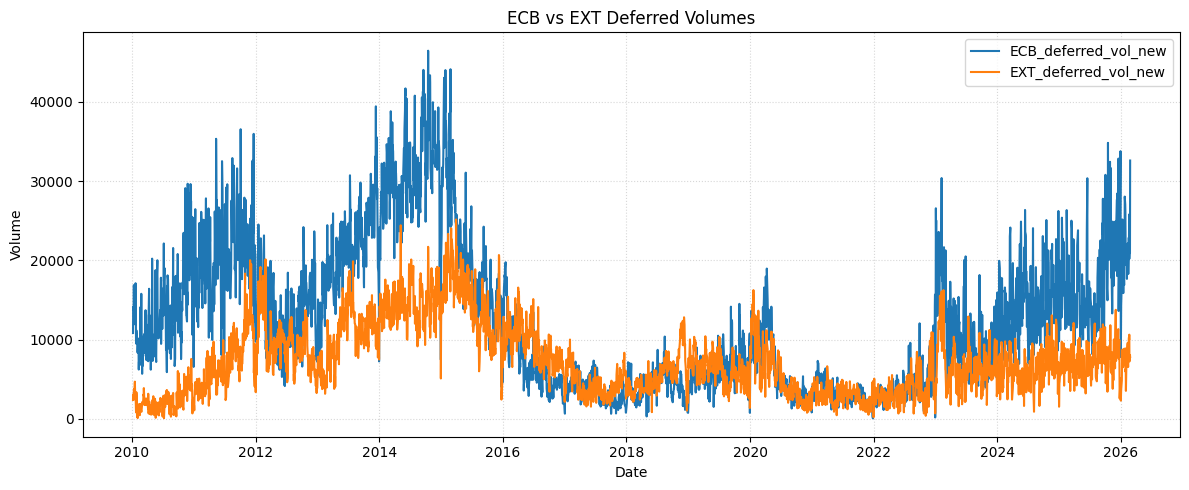

In [32]:
plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["ECB_deferred_vol_new"], label="ECB_deferred_vol_new")
plt.plot(df["Date"], df["EXT_deferred_vol_new"], label="EXT_deferred_vol_new")

plt.title("ECB vs EXT Deferred Volumes")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.grid(True, linestyle="dotted", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

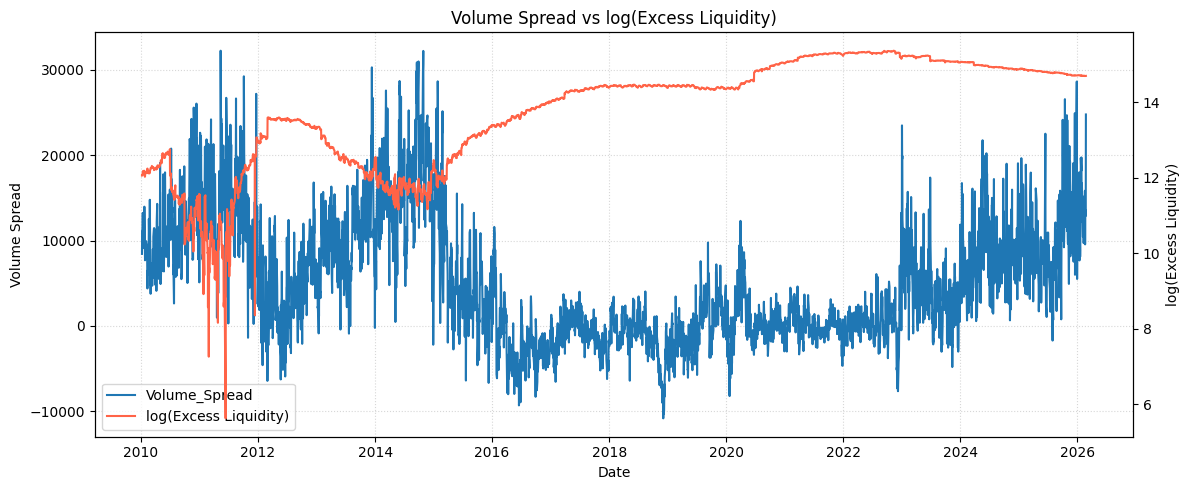

In [33]:
# -----------------------------
# 6) Volume Spread vs log(Excess Liquidity)
# -----------------------------
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df["Date"], df["Volume_Spread"], label="Volume_Spread")
ax1.set_xlabel("Date")
ax1.set_ylabel("Volume Spread")

ax2 = ax1.twinx()
ax2.plot(df["Date"], df["ExcessLiquidityLn"], label="log(Excess Liquidity)", color = "tomato")
ax2.set_ylabel("log(Excess Liquidity)")

ax1.set_title("Volume Spread vs log(Excess Liquidity)")
ax1.grid(True, linestyle="dotted", alpha=0.5)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

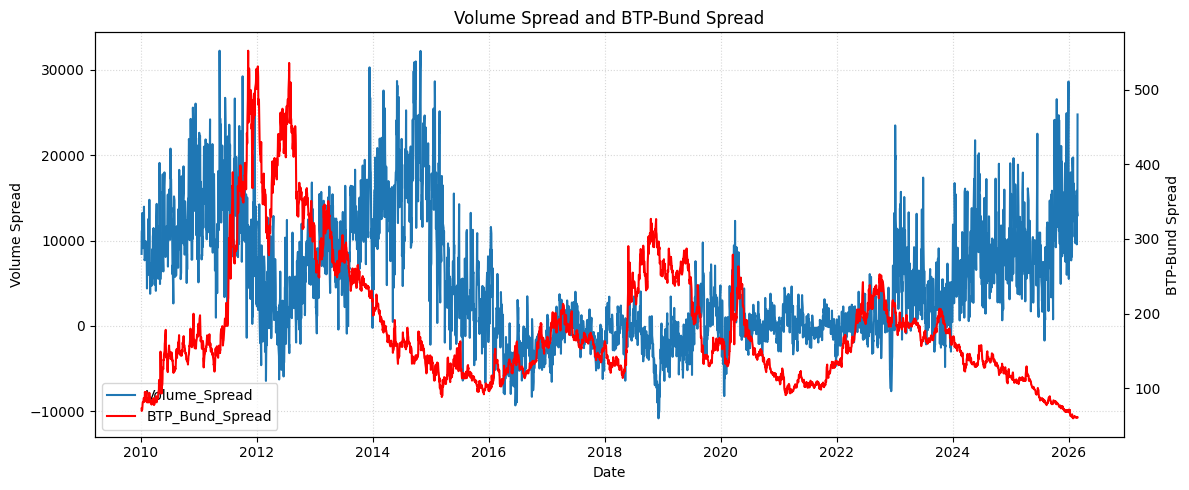

In [28]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Left axis
ax1.plot(df["Date"], df["Volume_Spread"], label="Volume_Spread")
ax1.set_xlabel("Date")
ax1.set_ylabel("Volume Spread")

# Right axis
ax2 = ax1.twinx()
ax2.plot(df["Date"], df["BTP_Bund_Spread"], label="BTP_Bund_Spread", color="red")
ax2.set_ylabel("BTP-Bund Spread")

# Title + grid
ax1.set_title("Volume Spread and BTP-Bund Spread")
ax1.grid(True, linestyle="dotted", alpha=0.5)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

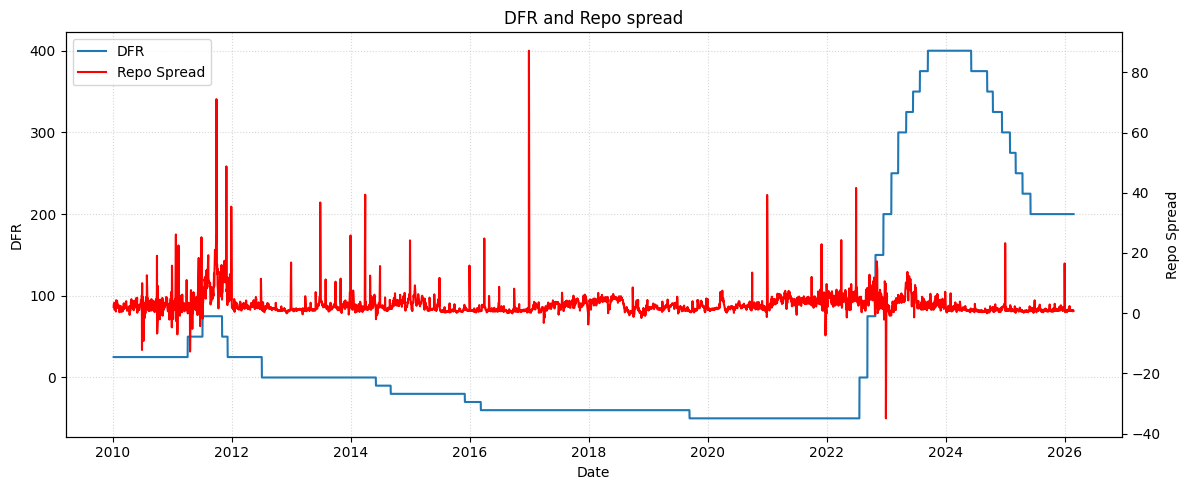

In [40]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Left axis
ax1.plot(df["Date"], df["DFR"], label="DFR")
ax1.set_xlabel("Date")
ax1.set_ylabel("DFR")

# Right axis
ax2 = ax1.twinx()
ax2.plot(df["Date"], df["DeferredRateSpread"], label="Repo Spread", color="red")
ax2.set_ylabel("Repo Spread")

# Title + grid
ax1.set_title("DFR and Repo spread")
ax1.grid(True, linestyle="dotted", alpha=0.5)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

KeyError: 'Stress_State'

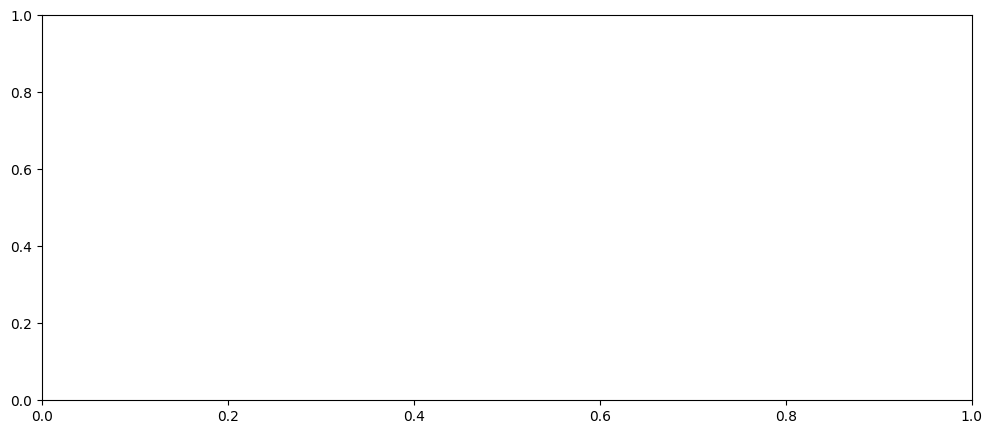

In [30]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Left axis
ax1.plot(df["Date"], df["Stress_State"], label="CISS")
ax1.set_xlabel("Date")
ax1.set_ylabel("CISS financial intermediaries subindex")

# Right axis
ax2 = ax1.twinx()
ax2.plot(df["Date"], df["DeferredRateSpread"], label="Repo Spread", color="red")
ax2.set_ylabel("Repo Spread")

# Title + grid
ax1.set_title("CISS financial intermediaries subindex and Repo spread")
ax1.grid(True, linestyle="dotted", alpha=0.5)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

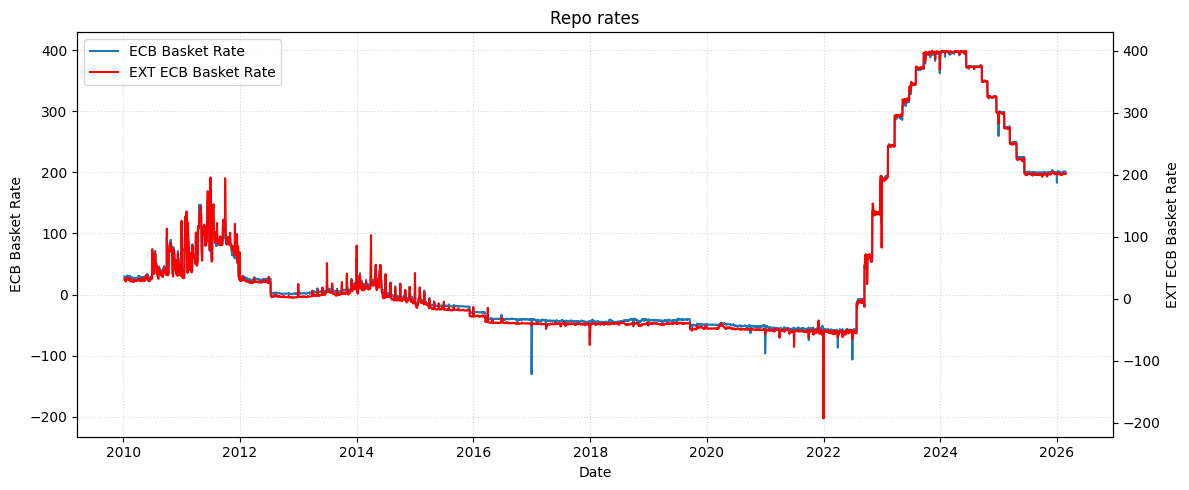

In [31]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Left axis
ax1.plot(df["Date"], df["ECB_deferred_rate_new"], label="ECB Basket Rate")
ax1.set_xlabel("Date")
ax1.set_ylabel("ECB Basket Rate")

# Right axis
ax2 = ax1.twinx()
ax2.plot(df["Date"], df["EXT_deferred_rate_new"], label="EXT ECB Basket Rate", color="red")
ax2.set_ylabel("EXT ECB Basket Rate")

# Title + grid
ax1.set_title("Repo rates")
ax1.grid(True, linestyle="dotted", alpha=0.5)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

# DATAFRAME STRUCTURE

In [41]:
df2 = df[[
    "Date",
    "ExcessLiquidity",
    "ExcessLiquidityLn",
    "BTP_Bund_Spread",
    "DeferredRateSpread",
    "ECB_deferred_vol_new",
    "EXT_deferred_vol_new",
    "Liquidity_ratio",
        "DFR",
    "ECB_deferred_rate_new", "EXT_deferred_rate_new", "DeferredVol", "DeferredRate"
    #"Stress_State"
]].dropna().copy()

print(df2.head())

        Date  ExcessLiquidity  ExcessLiquidityLn  BTP_Bund_Spread  \
2 2010-01-07           173038          12.061267             72.4   
3 2010-01-08           173038          12.061267             69.3   
4 2010-01-11           181959          12.111537             71.0   
5 2010-01-12           187010          12.138917             74.2   
6 2010-01-13           194958          12.180539             78.6   

   DeferredRateSpread  ECB_deferred_vol_new  EXT_deferred_vol_new  \
2            2.085330               10845.0                2407.0   
3            2.969748               14131.0                3075.0   
4            3.444170               13776.0                2423.0   
5            1.939897               16885.0                3646.0   
6            1.156129               12875.0                3760.0   

   Liquidity_ratio   DFR  ECB_deferred_rate_new  EXT_deferred_rate_new  \
2         1.505323  25.0              29.670217              31.755546   
3         1.525066  25

In [43]:
# 1. Define the outlier boundaries (1st and 99th percentiles)
lower_cutoff = df2['DeferredRateSpread'].quantile(0.09)
upper_cutoff = df2['DeferredRateSpread'].quantile(0.99)

# 2. Create the cleaned dataframe
# We use .copy() to ensure we aren't working on a slice of the original df
df3 = df2[(df2['DeferredRateSpread'] > lower_cutoff) & 
               (df2['DeferredRateSpread'] < upper_cutoff)].copy()



In [44]:
df3['Log_DeferredRateSpread'] = np.log1p(df3['DeferredRateSpread'])
df3['Log_BTP_Bund_Spread'] = np.log1p(df3['BTP_Bund_Spread'])
df3['Lagged_Spread'] = df3['DeferredRateSpread'].shift(1)
df3['Delta_Liquidity'] = df3['ExcessLiquidityLn'].diff(30)
df3["Deferred_MA"] = df3["DeferredRateSpread"].rolling(window=5).mean()

In [45]:
df3.head()

,Date,ExcessLiquidity,ExcessLiquidityLn,BTP_Bund_Spread,DeferredRateSpread,ECB_deferred_vol_new,EXT_deferred_vol_new,Liquidity_ratio,DFR,ECB_deferred_rate_new,EXT_deferred_rate_new,DeferredVol,DeferredRate,Log_DeferredRateSpread,Log_BTP_Bund_Spread,Lagged_Spread,Delta_Liquidity,Deferred_MA
2,2010-01-07,173038,12.061267,72.4,2.085330,10845.0,2407.0,1.505323,25.0,29.670217,31.755546,13252.0,30.1,1.126659,4.295924,NaN,NaN,NaN
3,2010-01-08,173038,12.061267,69.3,2.969748,14131.0,3075.0,1.525066,25.0,28.515618,31.485366,17206.0,29.0,1.378703,4.252772,2.085330,NaN,NaN
4,2010-01-11,181959,12.111537,71.0,3.444170,13776.0,2423.0,1.737922,25.0,28.365157,31.809327,16199.0,28.9,1.491593,4.276666,2.969748,NaN,NaN
5,2010-01-12,187010,12.138917,74.2,1.939897,16885.0,3646.0,1.532795,25.0,27.985336,29.925233,20531.0,28.4,1.078375,4.320151,3.444170,NaN,NaN
6,2010-01-13,194958,12.180539,78.6,1.156129,12875.0,3760.0,1.230868,25.0,27.346796,28.502926,16635.0,27.6,0.768315,4.377014,1.939897,NaN,2.319055


# Rolling Window analysis

Negative/zero spread rows: 0


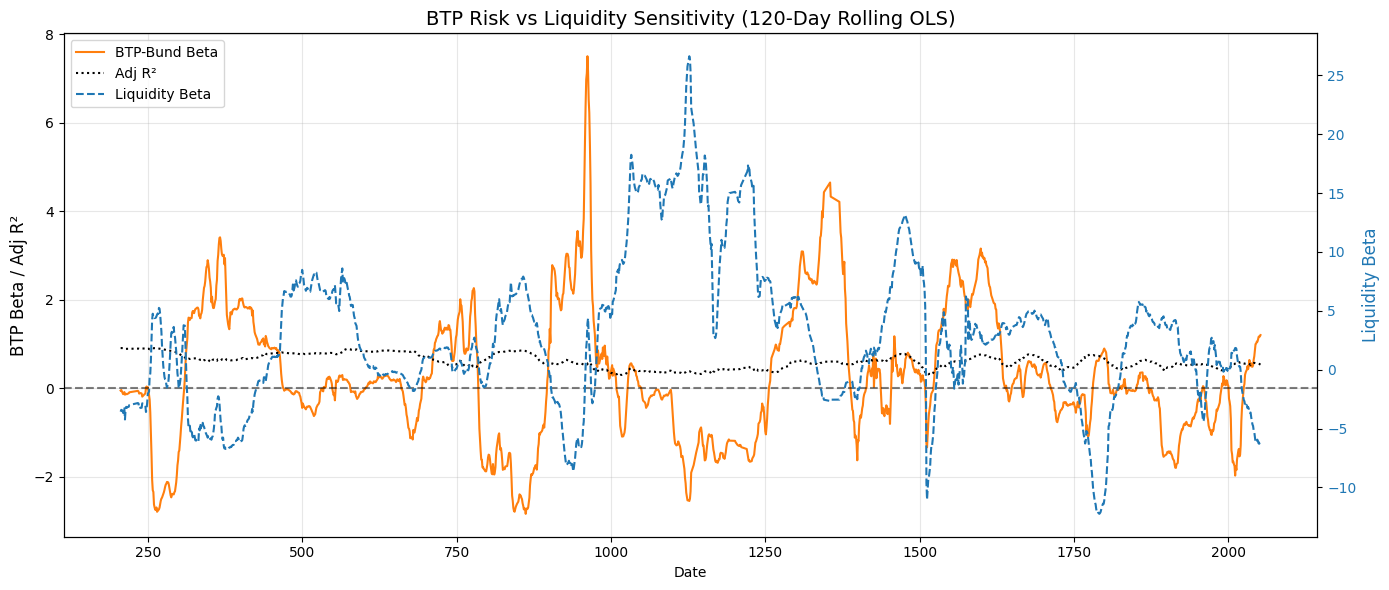

In [16]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# 1. Check for negative spread values before logging
print(f"Negative/zero spread rows: {(df3['DeferredRateSpread'] <= 0).sum()}")

# 2. Prepare data
df3['Lagged_Log_Spread'] = df3['Log_DeferredRateSpread'].shift(1)
df_rolling = df3.dropna(subset=['Lagged_Spread', 
                                 'ExcessLiquidityLn', 
                                 'Log_BTP_Bund_Spread',
                                 'DFR','Delta_Liquidity']).copy()

# 3. Parameters
window    = 120
betas_btp = []
betas_liq = []
betas_del = []
dates     = []
r2_vals = []
# 4. Rolling loop
for i in range(window, len(df_rolling)):
    #window_data = df_rolling.iloc[0:i]

#for i in range(window, len(df_rolling)):
    window_data = df_rolling.iloc[i - window:i]
    
    y = window_data['Deferred_MA']
    X = window_data[['Log_BTP_Bund_Spread', #'Delta_Liquidity', 
                      'Lagged_Log_Spread', 
                     'ExcessLiquidityLn',
                     #'DFR', #'Delta_Liquidity'
                    ]]
    X = sm.add_constant(X)
    
    model = sm.OLS(y, X).fit()
    r2_vals.append(model.rsquared_adj)   # use adjusted R²
    betas_btp.append(model.params['Log_BTP_Bund_Spread'])
    #betas_liq.append(model.params['ExcessLiquidityLn'])
    betas_del.append(model.params['ExcessLiquidityLn'])
    dates.append(df_rolling.index[i])

# 5. Plot
fig, ax1 = plt.subplots(figsize=(14, 6))

# LEFT AXIS → BTP beta + R²
color1 = 'tab:orange'
ax1.set_xlabel('Date')
ax1.set_ylabel('BTP Beta / Adj R²', fontsize=12)

ax1.plot(dates, betas_btp, color=color1, linewidth=1.5, label='BTP-Bund Beta')
ax1.plot(dates, r2_vals, color='black', linestyle=':', linewidth=1.5, label='Adj R²')

ax1.tick_params(axis='y')
ax1.axhline(0, color='black', linestyle='--', alpha=0.5)
ax1.grid(True, alpha=0.3)

# RIGHT AXIS → Liquidity beta
ax2 = ax1.twinx()
color2 = 'tab:blue'
ax2.set_ylabel('Liquidity Beta', color=color2, fontsize=12)

ax2.plot(dates, betas_del, color=color2, linewidth=1.5,
         linestyle='--', label='Liquidity Beta')

ax2.tick_params(axis='y', labelcolor=color2)

# Combined legend (include all lines)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title(f'BTP Risk vs Liquidity Sensitivity ({window}-Day Rolling OLS)', fontsize=14)
fig.tight_layout()
plt.show()

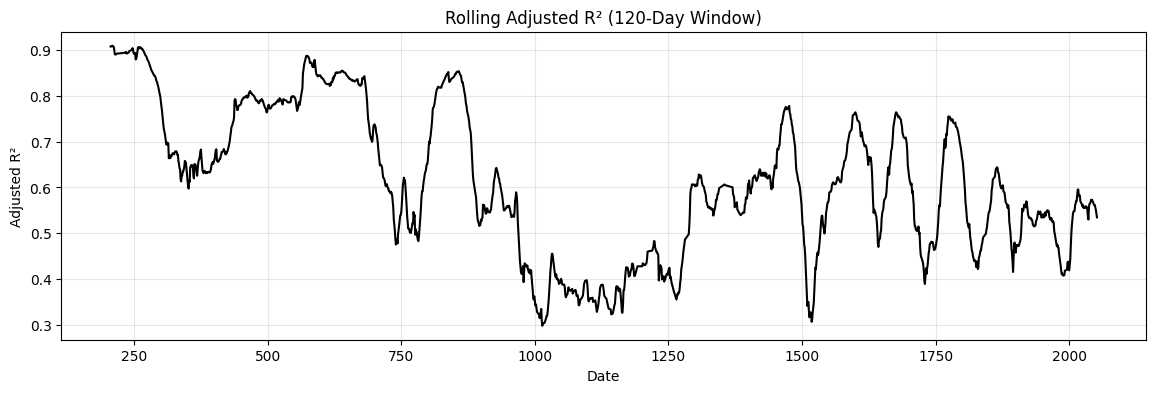

In [17]:
plt.figure(figsize=(14, 4))
plt.plot(dates, r2_vals, color='black', linewidth=1.5)
plt.title(f'Rolling Adjusted R² ({window}-Day Window)')
plt.xlabel('Date')
plt.ylabel('Adjusted R²')
plt.grid(alpha=0.3)
plt.show()

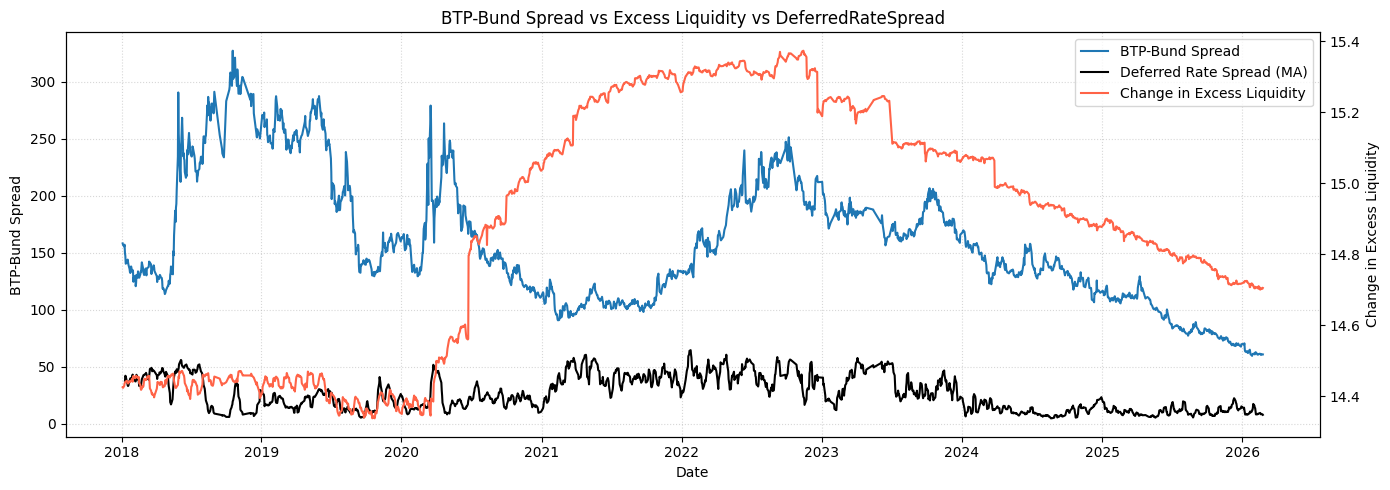

In [18]:
df3['dummy']= df3["Deferred_MA"]*10
df3['Delta_Liquidity']= df3["ExcessLiquidityLn"].diff(60)

fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(df3["Date"], df3["BTP_Bund_Spread"], label="BTP-Bund Spread")
ax1.set_xlabel("Date")
ax1.set_ylabel("BTP-Bund Spread")
ax1.plot(df3["Date"], df3["dummy"],
         label="Deferred Rate Spread (MA)", color="black")
ax2 = ax1.twinx()
ax2.plot(df3["Date"], df3["ExcessLiquidityLn"], label="Change in Excess Liquidity", color = "tomato")
ax2.set_ylabel("Change in Excess Liquidity")

ax1.set_title("BTP-Bund Spread vs Excess Liquidity vs DeferredRateSpread")
ax1.grid(True, linestyle="dotted", alpha=0.5)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()

# Data Modelling

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Setup the figure
plt.figure(figsize=(10, 6))

# 2. Plot the actual data distribution (Histogram + KDE)
# We use the original df2 to see the real "spikes"
sns.histplot(df2['DeferredRateSpread'], kde=True, element="step", 
             color="skyblue", stat="density", label='Actual Data (KDE)')

# 3. Calculate mean and standard deviation for the theoretical Normal Curve
mu, std = df2['DeferredRateSpread'].mean(), df2['DeferredRateSpread'].std()

# 4. Generate the Normal Distribution curve points
x = np.linspace(df2['DeferredRateSpread'].min(), df2['DeferredRateSpread'].max(), 100)
p = norm.pdf(x, mu, std)

# 5. Plot the theoretical Normal Curve (The "Bell Curve")
plt.plot(x, p, 'r', linewidth=2, label=f'Normal Dist (μ={mu:.2f}, σ={std:.2f})')

# 6. Formatting the chart
plt.title('Distribution of DeferredRateSpread vs. Normal Distribution', fontsize=14)
plt.xlabel('Spread (Basis Points)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Apply the Log-Plus-One transformation
# We add 1 to ensure all values are positive before logging
df2['Log_DeferredRateSpread'] = np.log1p(df2['DeferredRateSpread'])

# 2. Setup the figure
plt.figure(figsize=(10, 6))

# 3. Plot the Log-transformed distribution
sns.histplot(df2['Log_DeferredRateSpread'], kde=True, element="step", 
             color="mediumseagreen", stat="density", label='Log-Transformed Data')

# 4. Overlay the Normal Distribution for comparison
mu_log, std_log = df2['Log_DeferredRateSpread'].mean(), df2['Log_DeferredRateSpread'].std()
x = np.linspace(df2['Log_DeferredRateSpread'].min(), df2['Log_DeferredRateSpread'].max(), 100)
p = norm.pdf(x, mu_log, std_log)

plt.plot(x, p, 'r', linewidth=2, label=f'Normal Curve (μ={mu_log:.2f}, σ={std_log:.2f})')

# 5. Formatting
plt.title('Distribution of Log(DeferredRateSpread + 1)', fontsize=14)
plt.xlabel('Log-Spread Value')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Setup the figure
plt.figure(figsize=(10, 6))

# 2. Plot the actual data distribution (Histogram + KDE)
# We use the original df2 to see the real "spikes"
sns.histplot(df2['BTP_Bund_Spread'], kde=True, element="step", 
             color="skyblue", stat="density", label='Actual Data (KDE)')

# 3. Calculate mean and standard deviation for the theoretical Normal Curve
mu, std = df2['BTP_Bund_Spread'].mean(), df2['BTP_Bund_Spread'].std()

# 4. Generate the Normal Distribution curve points
x = np.linspace(df2['BTP_Bund_Spread'].min(), df2['BTP_Bund_Spread'].max(), 100)
p = norm.pdf(x, mu, std)

# 5. Plot the theoretical Normal Curve (The "Bell Curve")
plt.plot(x, p, 'r', linewidth=2, label=f'Normal Dist (μ={mu:.2f}, σ={std:.2f})')

# 6. Formatting the chart
plt.title('Distribution of BTP_Bund_Spread vs. Normal Distribution', fontsize=14)
plt.xlabel('Spread (Basis Points)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Apply Log transformation to BTP_Bund_Spread
# We use log1p in case the spread ever touches zero (unlikely but safe practice)
df2['Log_BTP_Bund_Spread'] = np.log1p(df2['BTP_Bund_Spread'])

# 2. Setup the figure
plt.figure(figsize=(10, 6))

# 3. Plot the Log-transformed distribution
sns.histplot(df2['Log_BTP_Bund_Spread'], kde=True, element="step", 
             color="orange", stat="density", label='Log(BTP-Bund Spread)')

# 4. Overlay the Normal Distribution curve
mu_btp, std_btp = df2['Log_BTP_Bund_Spread'].mean(), df2['Log_BTP_Bund_Spread'].std()
x = np.linspace(df2['Log_BTP_Bund_Spread'].min(), df2['Log_BTP_Bund_Spread'].max(), 100)
p = norm.pdf(x, mu_btp, std_btp)

plt.plot(x, p, 'k', linewidth=2, label=f'Normal Curve (μ={mu_btp:.2f}, σ={std_btp:.2f})')

# 5. Formatting
plt.title('Distribution of Log(BTP_Bund_Spread + 1)', fontsize=14)
plt.xlabel('Log-Spread Value')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Setup the figure
plt.figure(figsize=(10, 6))

# 2. Plot the actual data distribution (Histogram + KDE)
# We use the original df2 to see the real "spikes"
sns.histplot(df2['ExcessLiquidityLn'], kde=True, element="step", 
             color="skyblue", stat="density", label='Actual Data (KDE)')

# 3. Calculate mean and standard deviation for the theoretical Normal Curve
mu, std = df2['ExcessLiquidityLn'].mean(), df2['ExcessLiquidityLn'].std()

# 4. Generate the Normal Distribution curve points
x = np.linspace(df2['ExcessLiquidityLn'].min(), df2['ExcessLiquidityLn'].max(), 100)
p = norm.pdf(x, mu, std)

# 5. Plot the theoretical Normal Curve (The "Bell Curve")
plt.plot(x, p, 'r', linewidth=2, label=f'Normal Dist (μ={mu:.2f}, σ={std:.2f})')

# 6. Formatting the chart
plt.title('Distribution of ExcessLiquidityLn vs. Normal Distribution', fontsize=14)
plt.xlabel('Spread (Basis Points)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Setup the figure
plt.figure(figsize=(10, 6))

# 2. Plot the actual data distribution (Histogram + KDE)
# We use the original df2 to see the real "spikes"
sns.histplot(df_QE['Delta_Liquidity'], kde=True, element="step", 
             color="skyblue", stat="density", label='Actual Data (KDE)')

# 3. Calculate mean and standard deviation for the theoretical Normal Curve
mu, std = df_QE['Delta_Liquidity'].mean(), df_QE['Delta_Liquidity'].std()

# 4. Generate the Normal Distribution curve points
x = np.linspace(df_QE['Delta_Liquidity'].min(), df_QE['Delta_Liquidity'].max(), 100)
p = norm.pdf(x, mu, std)

# 5. Plot the theoretical Normal Curve (The "Bell Curve")
plt.plot(x, p, 'r', linewidth=2, label=f'Normal Dist (μ={mu:.2f}, σ={std:.2f})')

# 6. Formatting the chart
plt.title('Distribution of Change in ExcessLiquidity vs. Normal Distribution', fontsize=14)
plt.xlabel('Spread (Basis Points)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Setup the figure
plt.figure(figsize=(10, 6))

# 2. Plot the actual data distribution (Histogram + KDE)
# We use the original df2 to see the real "spikes"
sns.histplot(df_bQE['Delta_Liquidity'], kde=True, element="step", 
             color="skyblue", stat="density", label='Actual Data (KDE)')

# 3. Calculate mean and standard deviation for the theoretical Normal Curve
mu, std = df_bQE['Delta_Liquidity'].mean(), df_bQE['Delta_Liquidity'].std()

# 4. Generate the Normal Distribution curve points
x = np.linspace(df_bQE['Delta_Liquidity'].min(), df_bQE['Delta_Liquidity'].max(), 100)
p = norm.pdf(x, mu, std)

# 5. Plot the theoretical Normal Curve (The "Bell Curve")
plt.plot(x, p, 'r', linewidth=2, label=f'Normal Dist (μ={mu:.2f}, σ={std:.2f})')

# 6. Formatting the chart
plt.title('Distribution of Change in ExcessLiquidity vs. Normal Distribution', fontsize=14)
plt.xlabel('Spread (Basis Points)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Setup the figure
plt.figure(figsize=(10, 6))

# 2. Plot the actual data distribution (Histogram + KDE)
# We use the original df2 to see the real "spikes"
sns.histplot(df_QT['Delta_Liquidity'], kde=True, element="step", 
             color="skyblue", stat="density", label='Actual Data (KDE)')

# 3. Calculate mean and standard deviation for the theoretical Normal Curve
mu, std = df_QT['Delta_Liquidity'].mean(), df_QT['Delta_Liquidity'].std()

# 4. Generate the Normal Distribution curve points
x = np.linspace(df_QT['Delta_Liquidity'].min(), df_QT['Delta_Liquidity'].max(), 100)
p = norm.pdf(x, mu, std)

# 5. Plot the theoretical Normal Curve (The "Bell Curve")
plt.plot(x, p, 'r', linewidth=2, label=f'Normal Dist (μ={mu:.2f}, σ={std:.2f})')

# 6. Formatting the chart
plt.title('Distribution of Change in ExcessLiquidity vs. Normal Distribution', fontsize=14)
plt.xlabel('Spread (Basis Points)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

# Regime Shift Coding

In [22]:
# 1. Define the outlier boundaries (1st and 99th percentiles)
lower_cutoff = df2['BTP_Bund_Spread'].quantile(0.05)
upper_cutoff = df2['BTP_Bund_Spread'].quantile(0.95)

# 2. Create the cleaned dataframe
# We use .copy() to ensure we aren't working on a slice of the original df
df3 = df2[(df2['BTP_Bund_Spread'] > lower_cutoff) & 
               (df2['BTP_Bund_Spread'] < upper_cutoff)].copy()
df3['Log_DeferredRateSpread'] = np.log1p(df3['DeferredRateSpread'])
df3['Log_BTP_Bund_Spread'] = np.log1p(df3['BTP_Bund_Spread'])
df3['Lagged_Spread'] = df3['DeferredRateSpread'].shift(1)
df3['Delta_Liquidity'] = df3['ExcessLiquidityLn'].diff()
df3["Deferred_MA"] = df3["DeferredRateSpread"].rolling(window=5).mean()

C:\Users\shree\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [22]:
df3['ratio']=df3['Log_BTP_Bund_Spread']/df3['ExcessLiquidityLn']

df_QT  = df3[df3['Date'] >= "2022-07-01"].copy()

df_QE  = df3[(df3['Date'] >= "2021-02-01").copy()]

df_bQE = df3[(df3['Date'] >= "2018-07-01") & (df3['Date'] < "2021-02-01")].copy()


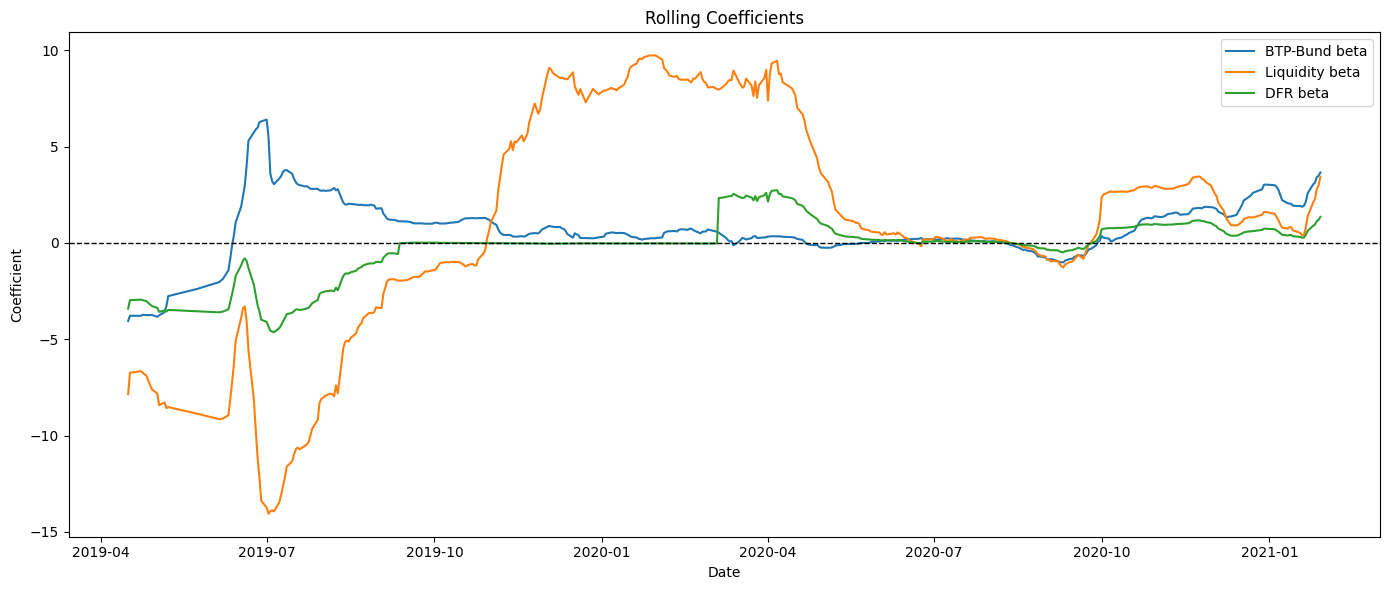

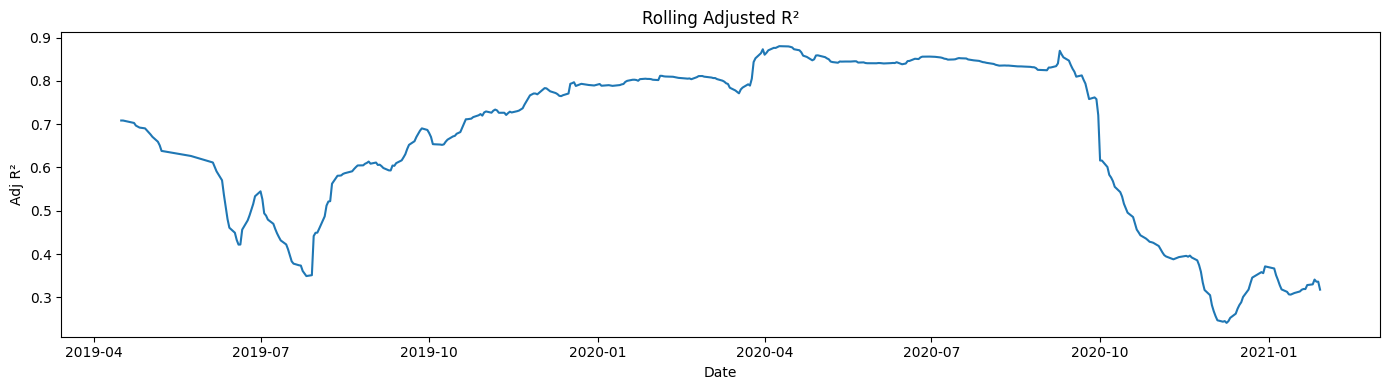

In [380]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Make sure data are sorted by date
df_bQE = df_bQE.sort_values("Date").reset_index(drop=True)

# Rolling window length
window = 120

# Storage
results = []

# Rolling loop
for i in range(window, len(df_bQE) + 1):
    window_data = df_bQE.iloc[i - window : i].copy()
    formula_shock = (
        'Deferred_MA ~ '
        'Lagged_Spread + '
        'Log_BTP_Bund_Spread + '
        'Delta_Liquidity + '
        'ExcessLiquidityLn + '
        #'ratio +'
        'DFR'
    )

    model = smf.ols(formula=formula_shock, data=window_data).fit(
        cov_type='HAC', cov_kwds={'maxlags': 5}
    )

    results.append({
        'Date': window_data['Date'].iloc[-1],
        'Intercept': model.params.get('Intercept', np.nan),
        'Lagged_Spread': model.params.get('Lagged_Log_Spread', np.nan),
        'Log_BTP_Bund_Spread': model.params.get('Log_BTP_Bund_Spread', np.nan),
        'Delta_Liquidity': model.params.get('Delta_Liquidity', np.nan),
        'ExcessLiquidityLn': model.params.get('ExcessLiquidityLn', np.nan),
        'DFR': model.params.get('DFR', np.nan),
        'Adj_R2': model.rsquared_adj,
        'AIC': model.aic,
        'BIC': model.bic
    })

rolling_df = pd.DataFrame(results)

#print(rolling_df.head())
#print(rolling_df.tail())
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(rolling_df['Date'], rolling_df['Log_BTP_Bund_Spread'], label='BTP-Bund beta')
plt.plot(rolling_df['Date'], rolling_df['ExcessLiquidityLn'], label='Liquidity beta')
plt.plot(rolling_df['Date'], rolling_df['DFR'], label='DFR beta')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.legend()
plt.title('Rolling Coefficients')
plt.xlabel('Date')
plt.ylabel('Coefficient')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(rolling_df['Date'], rolling_df['Adj_R2'], label='Adjusted R²')
plt.title('Rolling Adjusted R²')
plt.xlabel('Date')
plt.ylabel('Adj R²')
plt.tight_layout()
plt.show()

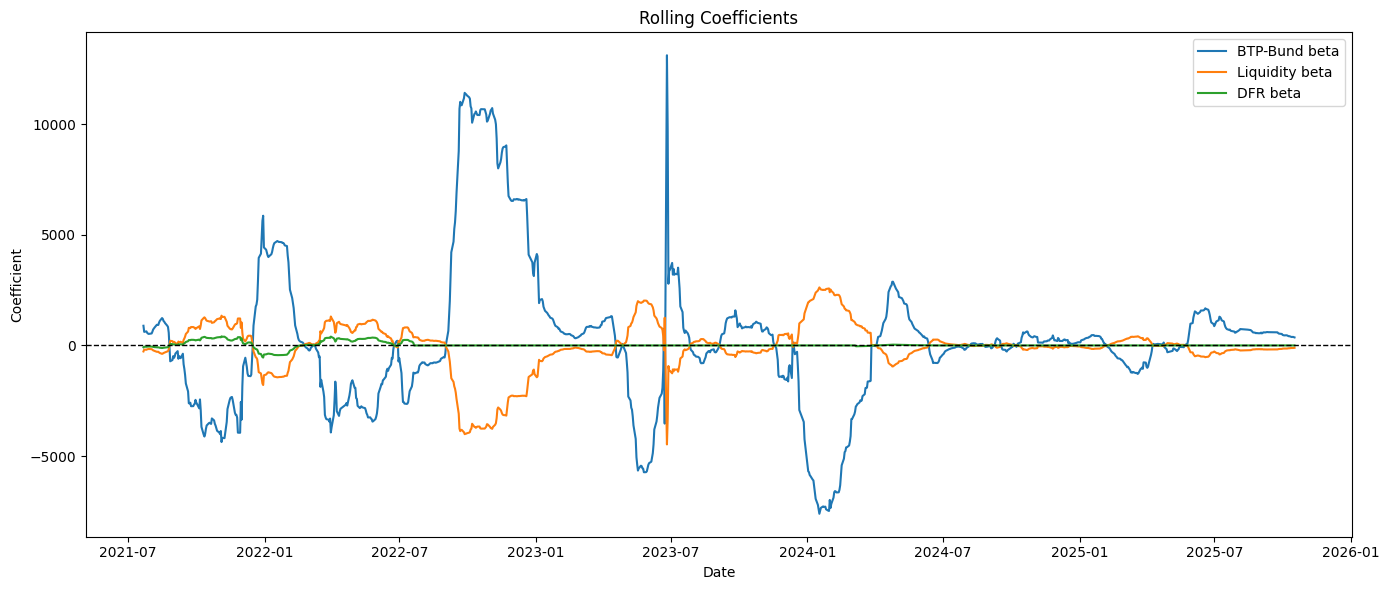

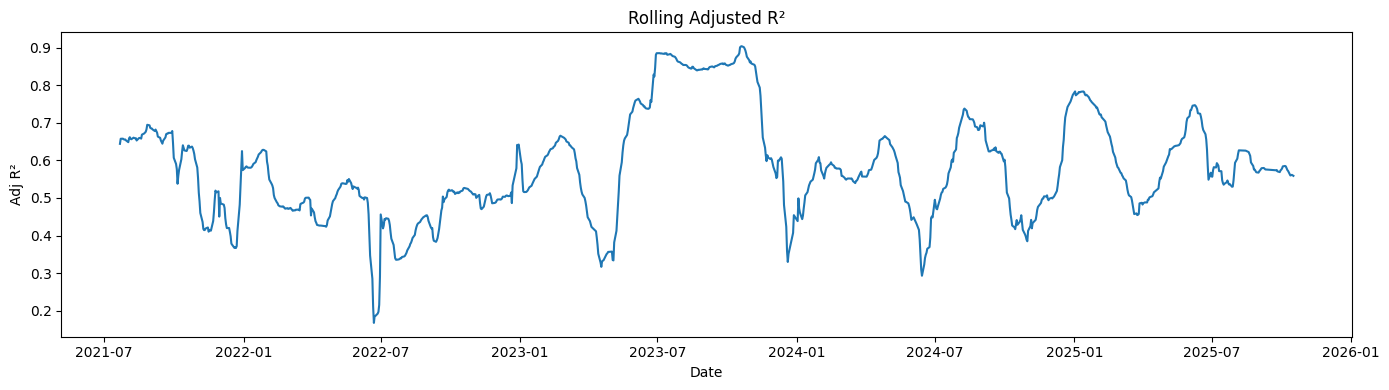

In [381]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Make sure data are sorted by date
df_QE = df_QE.sort_values("Date").reset_index(drop=True)

# Rolling window length
window = 120

# Storage
results = []

# Rolling loop
for i in range(window, len(df_QE) + 1):
    window_data = df_QE.iloc[i - window : i].copy() #window_data = df_QE.iloc[0:i].copy()

    formula_shock = (
        'Deferred_MA ~ '
        'Lagged_Spread + '
        'Log_BTP_Bund_Spread + '
        #'Delta_Liquidity + '
        'ExcessLiquidityLn + '
        'ratio +'
        'DFR'
    )

    model = smf.ols(formula=formula_shock, data=window_data).fit(
        cov_type='HAC', cov_kwds={'maxlags': 5}
    )

    results.append({
        'Date': window_data['Date'].iloc[-1],
        'Intercept': model.params.get('Intercept', np.nan),
        'Lagged_Spread': model.params.get('Lagged_Spread', np.nan),
        'Log_BTP_Bund_Spread': model.params.get('Log_BTP_Bund_Spread', np.nan),
        'Delta_Liquidity': model.params.get('Delta_Liquidity', np.nan),
        'ExcessLiquidityLn': model.params.get('ExcessLiquidityLn', np.nan),
        'DFR': model.params.get('DFR', np.nan),
        'Adj_R2': model.rsquared_adj,
        'AIC': model.aic,
        'BIC': model.bic
    })

rolling_df = pd.DataFrame(results)

#print(rolling_df.head())
#print(rolling_df.tail())
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(rolling_df['Date'], rolling_df['Log_BTP_Bund_Spread'], label='BTP-Bund beta')
plt.plot(rolling_df['Date'], rolling_df['ExcessLiquidityLn'], label='Liquidity beta')
plt.plot(rolling_df['Date'], rolling_df['DFR'], label='DFR beta')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.legend()
plt.title('Rolling Coefficients')
plt.xlabel('Date')
plt.ylabel('Coefficient')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(rolling_df['Date'], rolling_df['Adj_R2'], label='Adjusted R²')
plt.title('Rolling Adjusted R²')
plt.xlabel('Date')
plt.ylabel('Adj R²')
plt.tight_layout()
plt.show()

In [37]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Feature Engineering on df2

#df_bQE= df3[(df3['Date'] < "2020-03-01") ].copy()
# 5. The "Shock" Model Formula
# We include both the LEVEL and the CHANGE to see which one the market fears more
formula_shock = (
    'Deferred_MA ~ '
    'Lagged_Spread + '
    'Log_BTP_Bund_Spread + '
    'Delta_Liquidity + '    # The Daily Flow Shock
    'ExcessLiquidityLn + '  # The Stock Level
    'DFR'
)

model_shock = smf.ols(formula=formula_shock, data=df_bQE).fit(
    cov_type='HAC', cov_kwds={'maxlags': 5}
)

print(model_shock.summary())

                            OLS Regression Results                            
Dep. Variable:            Deferred_MA   R-squared:                       0.656
Model:                            OLS   Adj. R-squared:                  0.653
Method:                 Least Squares   F-statistic:                     27.37
Date:                Sun, 12 Apr 2026   Prob (F-statistic):           9.78e-25
Time:                        20:01:53   Log-Likelihood:                -515.99
No. Observations:                 549   AIC:                             1044.
Df Residuals:                     543   BIC:                             1070.
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -8.1375    

In [38]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Feature Engineering on df2

#df_QE= df3[(df3['Date'] >= "2020-03-01") & (df3['Date'] < "2022-09-01") ].copy()
# 5. The "Shock" Model Formula
# We include both the LEVEL and the CHANGE to see which one the market fears more
formula_shock = (
    'Deferred_MA ~ '
    'Lagged_Spread + '
    'Log_BTP_Bund_Spread + '
    'Delta_Liquidity + '    # The Daily Flow Shock
    #'ExcessLiquidityLn + '  # The Stock Level
    'DFR'
)

model_shock = smf.ols(formula=formula_shock, data=df_QE).fit(
    cov_type='HAC', cov_kwds={'maxlags': 5}
)

print(model_shock.summary())

                            OLS Regression Results                            
Dep. Variable:            Deferred_MA   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.678
Method:                 Least Squares   F-statistic:                     189.9
Date:                Sun, 12 Apr 2026   Prob (F-statistic):          2.13e-125
Time:                        20:01:55   Log-Likelihood:                -1986.7
No. Observations:                1172   AIC:                             3983.
Df Residuals:                    1167   BIC:                             4009.
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -7.6041    

In [39]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Feature Engineering on df2

#df_QT= df3[(df3['Date'] > "2022-09-01") ].copy()
# 5. The "Shock" Model Formula
# We include both the LEVEL and the CHANGE to see which one the market fears more
formula_shock = (
    'Deferred_MA ~ '
    'Lagged_Spread + '
    'Log_BTP_Bund_Spread + '
    'Delta_Liquidity + '    # The Daily Flow Shock
    'ExcessLiquidityLn + '  # The Stock Level
    'CISS'
)

model_shock = smf.ols(formula=formula_shock, data=df_QT).fit(
    cov_type='HAC', cov_kwds={'maxlags': 5}
)

print(model_shock.summary())

                            OLS Regression Results                            
Dep. Variable:            Deferred_MA   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.712
Method:                 Least Squares   F-statistic:                     95.99
Date:                Sun, 12 Apr 2026   Prob (F-statistic):           9.70e-80
Time:                        20:01:58   Log-Likelihood:                -1399.0
No. Observations:                 832   AIC:                             2810.
Df Residuals:                     826   BIC:                             2838.
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             -82.9772    

In [27]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Feature Engineering on df2

df_QT= df3[(df3['Date'] >= "2022-06-01") ].copy()
# 5. The "Shock" Model Formula
# We include both the LEVEL and the CHANGE to see which one the market fears more
formula_shock = (
    'Deferred_MA ~ '
    'Lagged_Spread + '
    'Log_BTP_Bund_Spread + '
    'Delta_Liquidity + '    # The Daily Flow Shock
    'ExcessLiquidityLn + '  # The Stock Level
    'DeferredRate'
)

model_shock = smf.ols(formula=formula_shock, data=df_QT).fit(
    cov_type='HAC', cov_kwds={'maxlags': 5}
)

print(model_shock.summary())

                            OLS Regression Results                            
Dep. Variable:            Deferred_MA   R-squared:                       0.703
Model:                            OLS   Adj. R-squared:                  0.701
Method:                 Least Squares   F-statistic:                     86.18
Date:                Sun, 12 Apr 2026   Prob (F-statistic):           6.47e-73
Time:                        20:00:58   Log-Likelihood:                -1413.8
No. Observations:                 832   AIC:                             2840.
Df Residuals:                     826   BIC:                             2868.
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             -87.9609    

In [28]:
import statsmodels.formula.api as smf

# Split by regime
df3['DFR_lag119'] = df3['DFR'].shift(119)
df_pre_hike  = df3[df3['DFR'] <  0].copy()
df_post_hike = df3[df3['DFR'] >= 0].copy()

print(f"Pre-hike obs:  {len(df_pre_hike)}")
print(f"Post-hike obs: {len(df_post_hike)}")

formula = (
    'Deferred_MA ~ '
    'Lagged_Spread + '
    'Log_BTP_Bund_Spread + '
    'ExcessLiquidityLn + '
    'DFR_lag119 +'
    'CISS'
)

model_pre  = smf.ols(formula, data=df_pre_hike).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
model_post = smf.ols(formula, data=df_post_hike).fit(cov_type='HAC', cov_kwds={'maxlags': 5})

print("\n── Pre-Hike Regime (DFR <= -0.5) ──")
print(model_pre.summary())

print("\n── Post-Hike Regime (DFR > -0.5) ──")
print(model_post.summary())

Pre-hike obs:  1046
Post-hike obs: 796

── Pre-Hike Regime (DFR <= -0.5) ──
                            OLS Regression Results                            
Dep. Variable:            Deferred_MA   R-squared:                       0.683
Model:                            OLS   Adj. R-squared:                  0.681
Method:                 Least Squares   F-statistic:                     166.7
Date:                Sun, 12 Apr 2026   Prob (F-statistic):          3.05e-126
Time:                        20:00:59   Log-Likelihood:                -1375.6
No. Observations:                 927   AIC:                             2763.
Df Residuals:                     921   BIC:                             2792.
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------

# One Model Fits All

In [29]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf


# 5. The "Shock" Model Formula
# We include both the LEVEL and the CHANGE to see which one the market fears more
formula_shock = (
    'Deferred_MA ~ '
    'Lagged_Spread +'
    'Log_BTP_Bund_Spread + '
    #'Delta_Liquidity  + ' 
    'ExcessLiquidityLn +'
    'DFR'
)

model_shock = smf.ols(formula=formula_shock, data=df3).fit(
    cov_type='HAC', cov_kwds={'maxlags': 5}
)

print(model_shock.summary())

                            OLS Regression Results                            
Dep. Variable:            Deferred_MA   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.678
Method:                 Least Squares   F-statistic:                     252.9
Date:                Sun, 12 Apr 2026   Prob (F-statistic):          3.70e-173
Time:                        20:01:14   Log-Likelihood:                -2886.6
No. Observations:                1838   AIC:                             5783.
Df Residuals:                    1833   BIC:                             5811.
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             -28.0530    

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Prepare Exogenous Variables (your 'Shock' drivers)
# We use the same lagged logic from your OLS
exog_vars = df3[['Lag_Log_BTP_Bund_Spread', 'Delta_Liquidity', 'Lag_DFR']].dropna()
endog_var = df3['Log_DeferredRateSpread'].loc[exog_vars.index]

# 2. Fit ARIMAX(1, 1, 1)
# (1, 1, 1) means: 1 Lag (AR), 1 Difference (I), 1 Error-Correction (MA)
model_arima = SARIMAX(endog_var, 
                      exog=exog_vars, 
                      order=(1, 1, 1), 
                      enforce_stationarity=False, 
                      enforce_invertibility=False)

results_arima = model_arima.fit(disp=False)
print(results_arima.summary())

In [ ]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing

# 1. Simple Exponential Smoothing (The "Level" model)
# Good for checking if the baseline is shifting
model_ses = SimpleExpSmoothing(df3['DeferredRateSpread']).fit(smoothing_level=0.2, optimized=False)
df3['SES_Level'] = model_ses.fittedvalues

# 2. Holt-Winters (Trend Model)
# This captures the 'Drift' as Liquidity drains
model_ets = ExponentialSmoothing(
    df3['DeferredRateSpread'], 
    trend='add', 
    seasonal=None 
).fit()

df3['ETS_Trend'] = model_ets.fittedvalues

# 3. Plotting the result against the raw data
plt.figure(figsize=(12,6))
plt.plot(df3['Date'], df3['DeferredRateSpread'], color='gray', alpha=0.3, label='Raw Log Spread')
plt.plot(df3['Date'], df3['ETS_Trend'], color='red', label='ETS Trend (The Structural Shift)')
plt.title('Exponential Smoothing: Identifying the QT Drift')
plt.legend()
plt.show()

# Volume Model

In [ ]:
df3.head()

# Finding the perfect Lag

In [ ]:
from sklearn.metrics import r2_score
import statsmodels.formula.api as smf

# Test lags from 1 to 90 days
lag_results = []

for lag in range(1, 250):
    df_temp = df3.copy()
    df_temp[f'DFR_lag{lag}'] = df_temp['DFR'].shift(lag)
    df_temp = df_temp.dropna()
    
    formula = (
        f'Log_DeferredRateSpread ~ '
        f'Lagged_Log_Spread + '
        f'Log_BTP_Bund_Spread + '
        f'Delta_Liquidity + '
        f'DFR_lag{lag}'
    )
    
    model = smf.ols(formula, data=df_temp).fit()
    
    lag_results.append({
        'lag':     lag,
        'r2':      model.rsquared_adj,
        'aic':     model.aic,
        'bic':     model.bic,
        'p_dfr':   model.pvalues[f'DFR_lag{lag}']
    })

lag_df = pd.DataFrame(lag_results)

# Plot
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(lag_df['lag'], lag_df['r2'], color='steelblue', lw=1.5)
axes[0].set_ylabel('Adj R-squared')
axes[0].set_title('Model Performance by DFR Lag')
axes[0].grid(alpha=0.3)

axes[1].plot(lag_df['lag'], lag_df['aic'], color='tomato', lw=1.5)
axes[1].set_ylabel('AIC')
axes[1].grid(alpha=0.3)

axes[2].plot(lag_df['lag'], lag_df['p_dfr'], color='darkgreen', lw=1.5)
axes[2].axhline(0.05, color='black', lw=0.8, ls='--', label='p=0.05')
axes[2].set_ylabel('p-value DFR')
axes[2].set_xlabel('Lag (days)')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Best lag by each criterion
print(f"Best lag by Adj R2: {lag_df.loc[lag_df['r2'].idxmax(),  'lag']}")
print(f"Best lag by AIC:    {lag_df.loc[lag_df['aic'].idxmin(), 'lag']}")
print(f"Best lag by BIC:    {lag_df.loc[lag_df['bic'].idxmin(), 'lag']}")

In [ ]:
from sklearn.metrics import r2_score
import statsmodels.formula.api as smf
import pandas as pd
import matplotlib.pyplot as plt

# Test lags from 1 to 200 days
lag_results = []

for lag in range(1, 250):
    df_temp = df3.copy()
    df_temp[f'BTP_lag{lag}'] = df_temp['BTP_Bund_Spread'].shift(lag)
    df_temp = df_temp.dropna()
    
    formula = (
        f'DeferredRateSpread ~ '
        f'Lagged_Spread + '
        f'BTP_lag{lag} + '
        f'Delta_Liquidity + '
        f'DFR'
    )
    
    model = smf.ols(formula, data=df_temp).fit()
    
    lag_results.append({
        'lag':     lag,
        'r2':      model.rsquared_adj,
        'aic':     model.aic,
        'bic':     model.bic,
        'p_btp':   model.pvalues[f'BTP_lag{lag}']
    })

lag_df = pd.DataFrame(lag_results)

# Plot
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(lag_df['lag'], lag_df['r2'], lw=1.5)
axes[0].set_ylabel('Adj R-squared')
axes[0].set_title('Model Performance by BTP-Bund Lag')
axes[0].grid(alpha=0.3)

axes[1].plot(lag_df['lag'], lag_df['aic'], lw=1.5)
axes[1].set_ylabel('AIC')
axes[1].grid(alpha=0.3)

axes[2].plot(lag_df['lag'], lag_df['p_btp'], lw=1.5)
axes[2].axhline(0.05, lw=0.8, ls='--')
axes[2].set_ylabel('p-value BTP')
axes[2].set_xlabel('Lag (days)')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Best lag by each criterion
print(f"Best lag by Adj R2: {lag_df.loc[lag_df['r2'].idxmax(),  'lag']}")
print(f"Best lag by AIC:    {lag_df.loc[lag_df['aic'].idxmin(), 'lag']}")
print(f"Best lag by BIC:    {lag_df.loc[lag_df['bic'].idxmin(), 'lag']}")